# Pre-entrega 6 · Orquestador multi-agente (Código Tributario de Uruguay)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/matiasandrade7/llm-multi-agent-orchestrator/blob/main/notebooks/demo.ipynb)

Este notebook **demuestra el flujo de delegación**: un Supervisor decide en cada paso si interviene
el **Investigador** (RAG sobre el Código Tributario), el **Analista** (cálculos) o si ya se puede
responder.

Qué vas a ver:
1. Setup y topología del grafo (diagrama Mermaid).
2. Una consulta real que recorre **investigar → calcular → sintetizar**.
3. Una consulta que **solo investiga** (el analista no interviene).
4. Una consulta **fuera de tema** (el sistema declara que no hay evidencia, no inventa).
5. Cómo se aísla el contexto de cada agente.

> Requiere Python 3.12+. Si no tenés las API keys, ejecutá solo la sección **"Modo simulación"** al final.

## 1. Setup

In [4]:
import os, pathlib, sys

REPO_URL = "https://github.com/matiasandrade7/llm-multi-agent-orchestrator.git"

# En Colab clonamos el repo; si el notebook corre dentro del repo (local), no hace falta.
if not pathlib.Path("src").exists():
    if not pathlib.Path("llm-multi-agent-orchestrator").exists():
        !git clone {REPO_URL}
    %cd llm-multi-agent-orchestrator

!pip install -q -r requirements.txt

In [5]:
import getpass

try:
    from google.colab import userdata
except ImportError:
    from dotenv import load_dotenv
    load_dotenv()
    userdata = None

for name in ("GOOGLE_API_KEY", "PINECONE_API_KEY"):
    if userdata is not None:
        try:
            os.environ[name] = userdata.get(name)
        except (userdata.SecretNotFoundError, userdata.NotebookAccessError, userdata.TimeoutException):
            pass  # Secrets no disponible: se pide la clave a mano más abajo
    if not os.getenv(name):
        os.environ[name] = getpass.getpass(f"{name}: ")

faltan = [n for n in ("GOOGLE_API_KEY", "PINECONE_API_KEY") if not os.getenv(n)]
print("Faltan claves:", faltan or "ninguna")

Faltan claves: ninguna


## 2. Topología del grafo

El Supervisor está en el centro: cada especialista **siempre devuelve el control** al Supervisor,
y la arista condicional (`route`, anotada con `Literal`) decide el próximo nodo.

In [6]:
from src.bootstrap import build_real_graph
from src.runner import run_query, format_trace

graph = build_real_graph()          # se arma UNA vez: carga embeddings, Pinecone y el LLM
print(graph.get_graph().draw_mermaid())

modules.json:   0%|          | 0.00/387 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/498k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/57.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/655 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  471MB            

model.safetensors: downloading bytes:           |  0.00B            

... (5 outputs left out)

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/167 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/200 [00:00<?, ?B/s]

---
config:
  flowchart:
    curve: linear
---
graph TD;
	__start__([<p>__start__</p>]):::first
	supervisor(supervisor)
	research(research)
	analyst(analyst)
	finalize(finalize)
	__end__([<p>__end__</p>]):::last
	__start__ --> supervisor;
	analyst --> supervisor;
	research --> supervisor;
	supervisor -.-> analyst;
	supervisor -.-> finalize;
	supervisor -.-> research;
	finalize --> __end__;
	classDef default fill:#f2f0ff,line-height:1.2
	classDef first fill-opacity:0
	classDef last fill:#bfb6fc



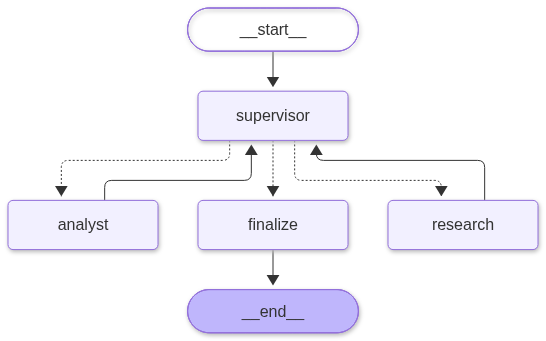

In [7]:
# Render opcional del diagrama (usa mermaid.ink, necesita internet). Si falla, queda el código de arriba.
from IPython.display import Image, display
try:
    display(Image(graph.get_graph().draw_mermaid_png()))
except Exception as exc:
    print("No se pudo renderizar el PNG:", type(exc).__name__)

## 3. Consulta 1 · camino completo (investigar → calcular → sintetizar)

La pregunta pide un **monto**, así que el Supervisor debe delegar primero en el Investigador
(para encontrar el artículo de la multa por mora) y después en el Analista (para calcularla).

In [8]:
from src.runner import save_trace

q1 = "Pagué con 100 días de atraso un tributo de $50.000. ¿Qué multa por mora corresponde y de cuánto sería?"
s1 = await run_query(graph, q1)

print(format_trace(s1))
print("\nDecisiones del supervisor:", s1["step_count"], "| errores:", s1["errors"] or "ninguno")
print("\n--- RESPUESTA FINAL ---\n", s1["final_answer"])
save_trace(s1, "traza_demo_1", origin="real");

/usr/local/lib/python3.13/dist-packages/langchain_google_genai/chat_models.py:3940: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(
/usr/local/lib/python3.13/dist-packages/langchain_google_genai/chat_models.py:3940: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(
/usr/local/lib/python3.13/dist-packages/langchain_google_genai/chat_models.py:3940: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(
/usr/local/lib/python3.13/dist-packages/langchain_google_genai/chat_models.py:3940: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_

 #  nodo        paso        ms  detalle
----------------------------------------------------------------------------------------------------
 1  supervisor     0    1502.1  → research · No hay evidencia en el sistema todavía. Según las reglas de flujo, el investigador debe buscar y citar los artículos pertinentes primero. · origen=llm
 2  research       1    2879.4  ok · herramientas: search_articles · artículos: 94, 93, 97, 98
 3  supervisor     1    1216.7  → research · La evidencia del investigador se cortó y no muestra el porcentaje exacto de multa para 100 días de atraso, por lo que se requiere un refinamiento de la búsqueda antes de proceder al cálculo. · origen=llm
 4  research       2    3847.6  ok · herramientas: read_article, search_articles · artículos: 94, 101, 93, 112
 5  supervisor     2    1299.1  → analyst · Ya se cuenta con la evidencia del investigador citando el artículo pertinente y su texto, por lo que corresponde que el analista realice el cálculo del monto y porc

In [9]:
# ¿Quién aportó qué? (el estado compartido registra cada contribución)
for c in s1["contributions"]:
    print(f"[{c['agent']:<8}] status={c['status']} · herramientas={c['tools_used']} · artículos={c['articles']} · {c['ms']:.0f} ms")

[research] status=ok · herramientas=['search_articles'] · artículos=['94', '93', '97', '98'] · 2879 ms
[research] status=ok · herramientas=['read_article', 'search_articles'] · artículos=['94', '101', '93', '112'] · 3848 ms
[analyst ] status=ok · herramientas=['calculate_percentage'] · artículos=[] · 2700 ms


## 4. Consulta 2 · solo investigar

No hay nada que calcular: el Supervisor **no** debería invocar al Analista.

In [10]:
q2 = "¿En cuántos años prescribe el derecho al cobro de los tributos y cuándo se amplía ese plazo?"
s2 = await run_query(graph, q2)

print(format_trace(s2))
print("\nAgentes que intervinieron:", [c["agent"] for c in s2["contributions"]])
print("\n--- RESPUESTA FINAL ---\n", s2["final_answer"])
save_trace(s2, "traza_demo_2", origin="real");

/usr/local/lib/python3.13/dist-packages/langchain_google_genai/chat_models.py:3940: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(
/usr/local/lib/python3.13/dist-packages/langchain_google_genai/chat_models.py:3940: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(
/usr/local/lib/python3.13/dist-packages/langchain_google_genai/chat_models.py:3940: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(
/usr/local/lib/python3.13/dist-packages/langchain_google_genai/chat_models.py:3940: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_

 #  nodo        paso        ms  detalle
----------------------------------------------------------------------------------------------------
 1  supervisor     0     828.0  → research · Es el primer paso obligatorio. No hay evidencia del investigador en el sistema y se requiere buscar los artículos pertinentes sobre la prescripción de tributos. · origen=llm
 2  research       1    3055.3  ok · herramientas: search_articles, read_article · artículos: 39, 38, 30, 49, 32
 3  supervisor     1    9699.0  → research · La contribución anterior del investigador quedó incompleta justo cuando detallaba la ampliación del plazo, por lo que es necesario un refinamiento para obtener el artículo completo sin cortes. · origen=llm
 4  research       2   40451.6  ok · herramientas: read_article · artículos: 38
 5  supervisor     2     752.6  → FINISH · El investigador ya citó correctamente el artículo 38 con el plazo general de cinco años y los supuestos de ampliación a diez años, cumpliendo la rúbrica.

## 5. Consulta 3 · fuera de tema (caso de control)

No hay evidencia en el Código Tributario. Lo correcto es **decirlo** en vez de inventar una receta
o un artículo.

In [11]:
q3 = "¿Cuál es la receta tradicional del chivito uruguayo?"
s3 = await run_query(graph, q3)

print(format_trace(s3))
print("\n--- RESPUESTA FINAL ---\n", s3["final_answer"])
save_trace(s3, "traza_demo_3", origin="real");

/usr/local/lib/python3.13/dist-packages/langchain_google_genai/chat_models.py:3940: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(
/usr/local/lib/python3.13/dist-packages/langchain_google_genai/chat_models.py:3940: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(
/usr/local/lib/python3.13/dist-packages/langchain_google_genai/chat_models.py:3940: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(
/usr/local/lib/python3.13/dist-packages/langchain_google_genai/chat_models.py:3940: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_

 #  nodo        paso        ms  detalle
----------------------------------------------------------------------------------------------------
 1  supervisor     0    1175.3  → research · Es el primer paso necesario para buscar evidencia en el Código Tributario según la regla 1. · origen=llm
 2  research       1    3271.1  ok · herramientas: search_articles · artículos: 108, 112, 94, 111, 51
 3  supervisor     1    1247.3  → FINISH · La pregunta sobre la receta del chivito uruguayo no corresponde al Código Tributario y no se puede responder con material tributario, por lo que se finaliza el flujo. · origen=llm
 4  finalize       2     748.7  modo=llm

--- RESPUESTA FINAL ---
 No se encontró ninguna mención sobre la receta tradicional del chivito uruguayo en la evidencia consultada, ya que el Código Tributario versa exclusivamente sobre materia tributaria, obligaciones fiscales, infracciones, sanciones y procedimientos administrativos en el ámbito fiscal.

Información orientativa basada e

## 6. Resumen de la delegación

Una fila por consulta: qué agentes intervinieron y cuántas decisiones tomó el Supervisor
(siempre acotadas por `MAX_STEPS`).

In [12]:
from src import config

print(f"{'consulta':<10} {'agentes':<22} {'decisiones':>10}  {'errores':>7}")
for i, s in enumerate((s1, s2, s3), 1):
    agentes = " → ".join(c["agent"] for c in s["contributions"]) or "(ninguno)"
    print(f"{i:<10} {agentes:<22} {s['step_count']:>10}  {len(s['errors']):>7}")
print(f"\nTecho de pasos configurado: MAX_STEPS={config.MAX_STEPS}, MAX_CALLS_PER_AGENT={config.MAX_CALLS_PER_AGENT}")

consulta   agentes                decisiones  errores
1          research → research → analyst          4        0
2          research → research             3        0
3          research                        2        0

Techo de pasos configurado: MAX_STEPS=6, MAX_CALLS_PER_AGENT=2


## 7. Aislamiento de contexto

Cada especialista recibe **solo** la pregunta original y la instrucción del Supervisor
(no el historial ni el prompt del Supervisor). Esta instrucción es lo único que "viaja":

In [13]:
for c in s1["contributions"]:
    print(f"[{c['agent']}] instrucción recibida del Supervisor:\n   {c['instruction']}\n")

[research] instrucción recibida del Supervisor:
   Busca y cita los artículos del Código Tributario de Uruguay que regulan la multa por mora y el recargo o tasa aplicable por pagos atrasados.

[research] instrucción recibida del Supervisor:
   El informe anterior quedó incompleto en la transcripción del Artículo 94 (multa por mora según el plazo). Por favor, busque nuevamente el texto completo del Artículo 94 y del Artículo 95 o 97 del Código Tributario para obtener con exactitud el porcentaje de multa aplicable a un atraso de 100 días, citando explícitamente los artículos correspondientes.

[analyst] instrucción recibida del Supervisor:
   Con base en el artículo 94 del Código Tributario citado por el investigador (100 días de atraso, tributo de $50.000), calcule el porcentaje de multa por mora aplicable y el monto resultante, explicitando la fórmula utilizada.



---
## Modo simulación (sin API keys)

Corre el **mismo grafo, el mismo Supervisor y las mismas herramientas**, pero con un LLM guionado y
un retriever léxico local. Sirve para ver el flujo de delegación sin gastar tokens. Las respuestas
quedan marcadas con `[SIMULACIÓN]`.

In [14]:
from src.simulation import SIM_QUESTION, build_simulation_graph

sim_graph, *_ = build_simulation_graph()
sim = await run_query(sim_graph, SIM_QUESTION)
print(format_trace(sim))
print("\n", sim["final_answer"])

 #  nodo        paso        ms  detalle
----------------------------------------------------------------------------------------------------
 1  supervisor     0       0.1  → research · Todavía no hay evidencia: hay que investigar primero. · origen=llm
 2  research       1      35.7  ok · herramientas: search_articles, read_article · artículos: 33, 93, 94, 97
 3  supervisor     1       0.1  → analyst · La pregunta pide un monto y ya hay artículo citado. · origen=llm
 4  analyst        2       7.9  ok · herramientas: calculate_percentage · artículos: -
 5  supervisor     2       0.1  → FINISH · Rúbrica cumplida: artículo citado, cálculo con fórmula y dato faltante declarado. · origen=llm
 6  finalize       3       1.6  modo=llm

 [SIMULACIÓN] Al pagar con 100 días de atraso corresponde la multa del 20% sobre el tributo no pagado en término (Art. 94, literal C). Sobre $50.000, la multa es de $10.000. Además se aplica un recargo mensual, cuya tasa fija el Poder Ejecutivo y no figura en el